In [1]:
# Libraries for data handling, charts, and saving models
import os
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# scikit-learn tools for splitting data, preprocessing, models, and scoring
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline

In [2]:
# Load the UNSW-NB15 training data and show the first 5 rows
df = pd.read_csv('UNSW_NB15_training-set.csv')
df.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [3]:
# Number of rows and columns
df.shape

(175341, 45)

In [4]:
# Count missing values in each column
df.isna().sum()

id                   0
dur                  0
proto                0
service              0
state                0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sttl                 0
dttl                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_srv_src           0
ct_state_ttl         0
ct_dst_ltm           0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
ct_dst_src_ltm       0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
ct_src_ltm           0
ct_srv_dst           0
is_sm_ips_ports      0
attack_cat 

In [5]:
# Count rows that are exact duplicates
df.duplicated().sum()

np.int64(0)

In [6]:
# Column names, data types, and how many values are filled in
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  str    
 3   service            175341 non-null  str    
 4   state              175341 non-null  str    
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  sinpkt       

In [7]:
# Data type of each column
df.dtypes

id                     int64
dur                  float64
proto                    str
service                  str
state                    str
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             int64
ct_state_ttl           int64
ct_dst_ltm             int64
ct_src_dport_l

In [8]:
# How many rows are normal (0) and how many are attacks (1)
df['label'].value_counts()

label
1    119341
0     56000
Name: count, dtype: int64

In [9]:
# in percentage
df['label'].value_counts(normalize=True) * 100

label
1    68.062233
0    31.937767
Name: proportion, dtype: float64

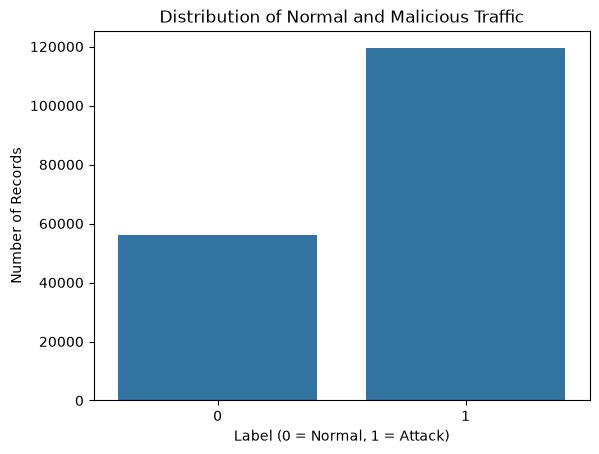

In [10]:
# Bar chart of normal vs attack traffic
sns.countplot(data=df, x="label")

plt.title("Distribution of Normal and Malicious Traffic")
plt.xlabel("Label (0 = Normal, 1 = Attack)")
plt.ylabel("Number of Records")
plt.show()

In [11]:
# Number of rows for each attack category
df['attack_cat'].value_counts()

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

In [12]:
# Attack categories as a percentage of all rows
df["attack_cat"].value_counts(normalize=True) * 100

attack_cat
Normal            31.937767
Generic           22.812691
Exploits          19.044605
Fuzzers           10.370649
DoS                6.994371
Reconnaissance     5.983198
Analysis           1.140635
Backdoor           0.995774
Shellcode          0.646169
Worms              0.074141
Name: proportion, dtype: float64

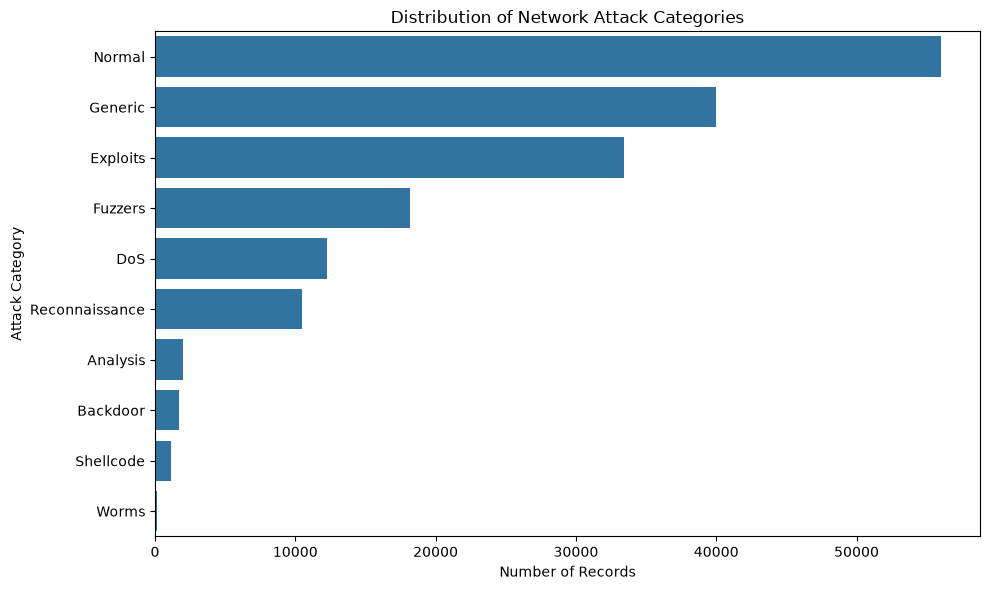

In [13]:
# Bar chart of attack categories, largest first
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="attack_cat",
    order=df["attack_cat"].value_counts().index
)

plt.title("Distribution of Network Attack Categories")
plt.xlabel("Number of Records")
plt.ylabel("Attack Category")
plt.tight_layout()
plt.show()

In [14]:
# The 10 most common network protocols
top_protos = df['proto'].value_counts().head(10)

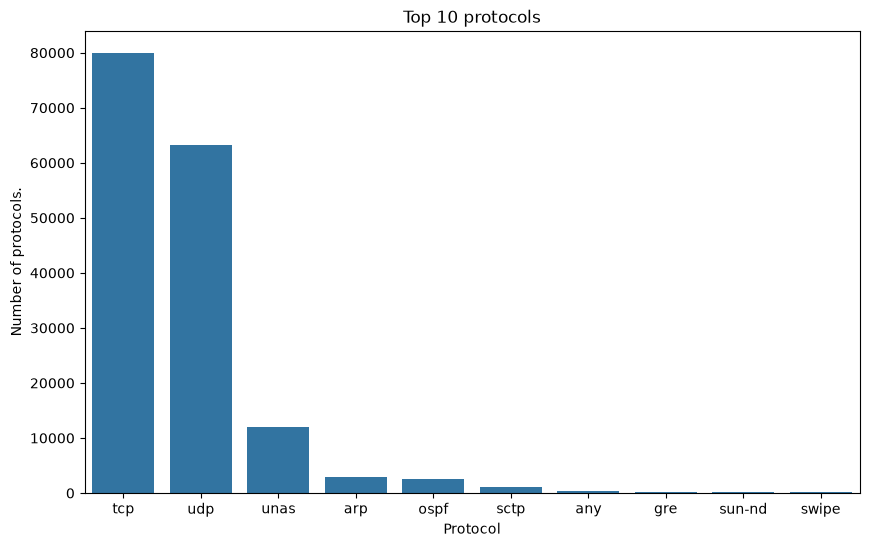

In [15]:
# Bar chart of the top 10 protocols
plt.figure(figsize=(10, 6))
sns.barplot(x=top_protos.index, y=top_protos.values)
plt.title("Top 10 protocols")
plt.xlabel("Protocol")
plt.ylabel("Number of protocols.")
plt.show()

In [16]:
# Services (http, dns, ftp...) as a percentage of all rows
df['service'].value_counts(normalize=True) * 100

service
-           53.705636
dns         26.972585
http        10.678621
smtp         2.884665
ftp-data     2.278417
ftp          1.955048
ssh          0.742553
pop3         0.630201
dhcp         0.053610
snmp         0.045625
ssl          0.031938
irc          0.014258
radius       0.006844
Name: proportion, dtype: float64

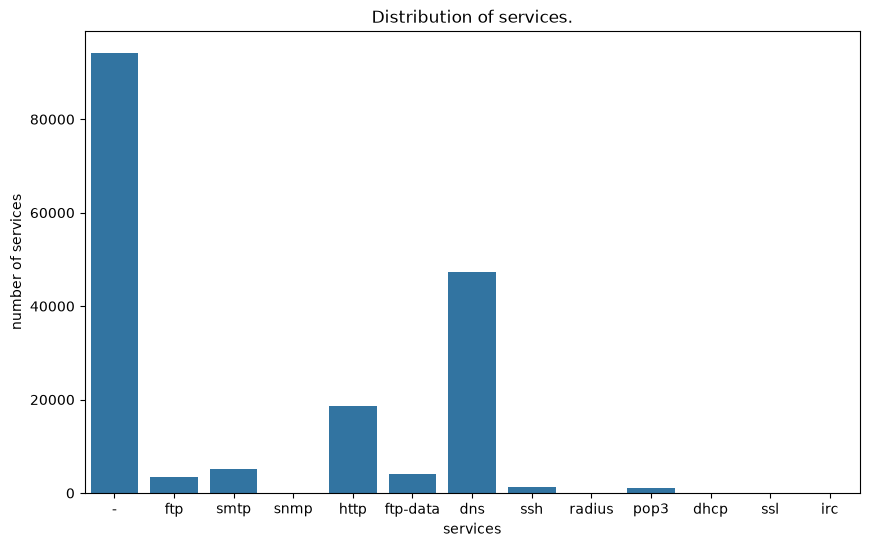

In [17]:
# Bar chart of how often each service appears
plt.figure(figsize=(10,6))
sns.countplot(
    data=df,
    x='service'
)
plt.title('Distribution of services.')
plt.xlabel('services')
plt.ylabel('number of services')
plt.show()

In [18]:
# Number of rows for each connection state
df['state'].value_counts()

state
INT    82275
FIN    77825
CON    13152
REQ     1991
RST       83
ECO       12
PAR        1
URN        1
no         1
Name: count, dtype: int64

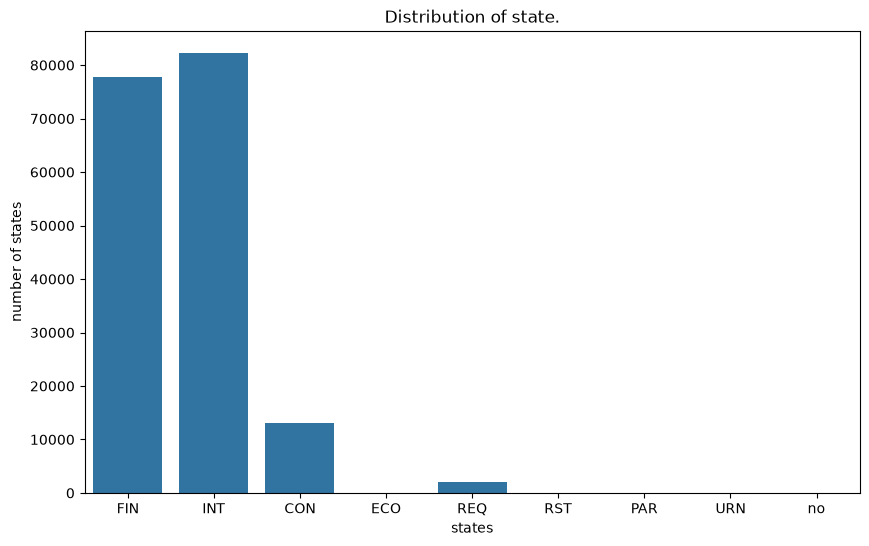

In [19]:
# Bar chart of connection states
plt.figure(figsize=(10,6))
sns.countplot(
    data=df,
    x='state'
)
plt.title('Distribution of state.')
plt.xlabel('states')
plt.ylabel('number of states')
plt.show()

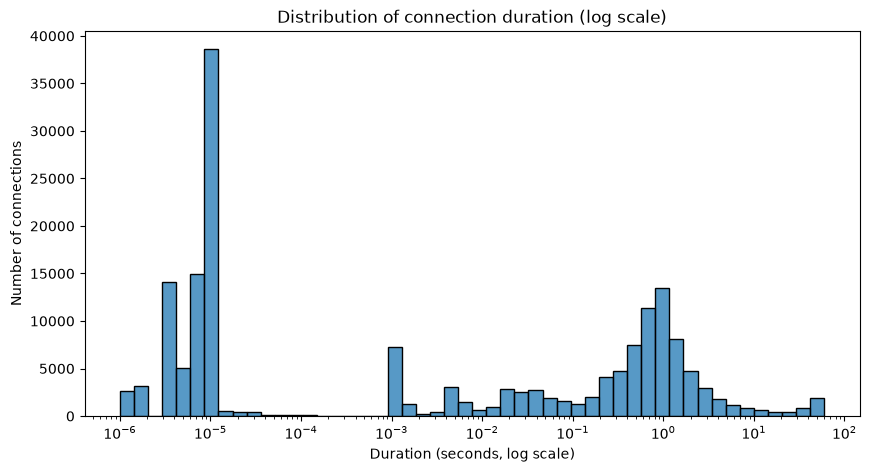

In [20]:
# Histogram of connection duration
# A tiny value (1e-6) is added so durations of 0 still work on the log scale
plt.figure(figsize=(10, 5))
sns.histplot(df['dur'] + 1e-6, bins=50, log_scale=True)
plt.title("Distribution of connection duration (log scale)")
plt.xlabel("Duration (seconds, log scale)")
plt.ylabel("Number of connections")
plt.show()

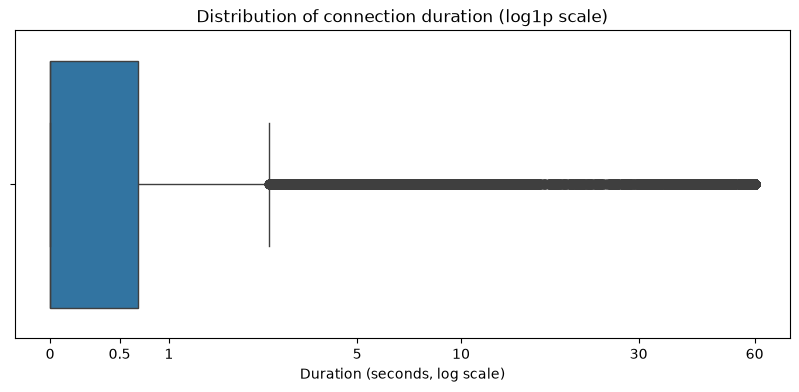

In [21]:
# Box plot of duration after log1p, with tick labels shown in real seconds
plt.figure(figsize=(10, 4))
sns.boxplot(x=np.log1p(df['dur']))
plt.title("Distribution of connection duration (log1p scale)")
ticks = [0, 0.5, 1, 5, 10, 30, 60]
plt.xticks(np.log1p(ticks), ticks)
plt.xlabel("Duration (seconds, log scale)")
plt.show()

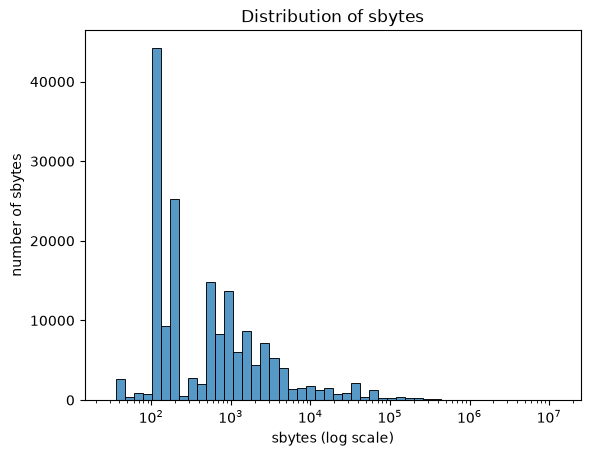

In [22]:
# Histogram of bytes sent by the source (log scale)
sns.histplot(df['sbytes'], bins=50, log_scale=True)
plt.title("Distribution of sbytes")
plt.xlabel("sbytes (log scale)")
plt.ylabel("number of sbytes")
plt.show()

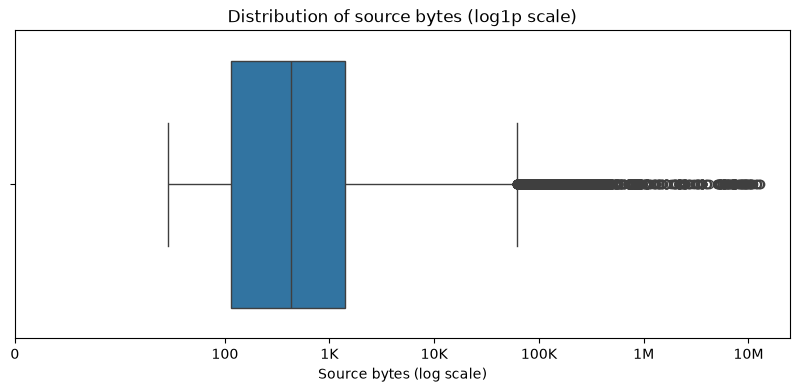

In [23]:
# Box plot of source bytes after log1p, with easy-to-read tick labels
plt.figure(figsize=(10, 4))
sns.boxplot(x=np.log1p(df['sbytes']))
plt.title("Distribution of source bytes (log1p scale)")
ticks = [0, 100, 1_000, 10_000, 100_000, 1_000_000, 10_000_000]
plt.xticks(np.log1p(ticks), ['0', '100', '1K', '10K', '100K', '1M', '10M'])
plt.xlabel("Source bytes (log scale)")
plt.show()

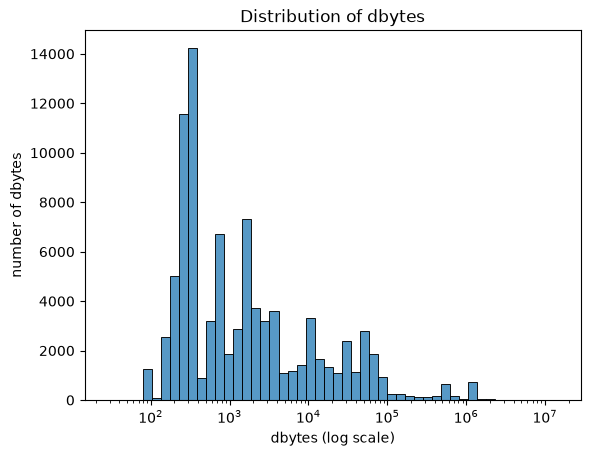

In [24]:
# Histogram of bytes sent by the destination (log scale)
sns.histplot(df['dbytes'], bins=50, log_scale=True)
plt.title("Distribution of dbytes")
plt.xlabel("dbytes (log scale)")
plt.ylabel("number of dbytes")
plt.show()

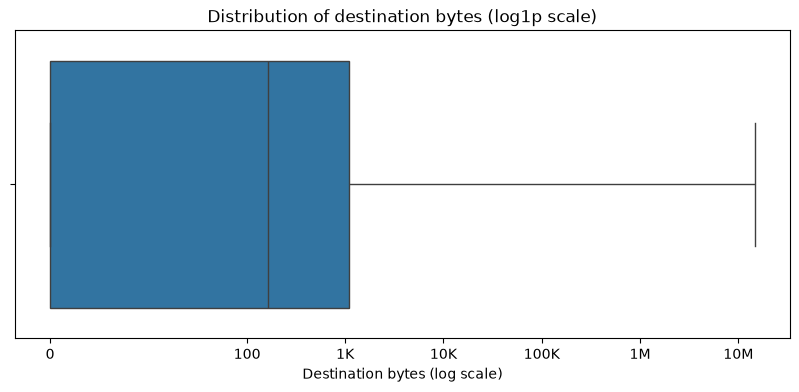

In [25]:
# Box plot of destination bytes after log1p, with easy-to-read tick labels
plt.figure(figsize=(10, 4))
sns.boxplot(x=np.log1p(df['dbytes']))
plt.title("Distribution of destination bytes (log1p scale)")
ticks = [0, 100, 1_000, 10_000, 100_000, 1_000_000, 10_000_000]
plt.xticks(np.log1p(ticks), ['0', '100', '1K', '10K', '100K', '1M', '10M'])
plt.xlabel("Destination bytes (log scale)")
plt.show()

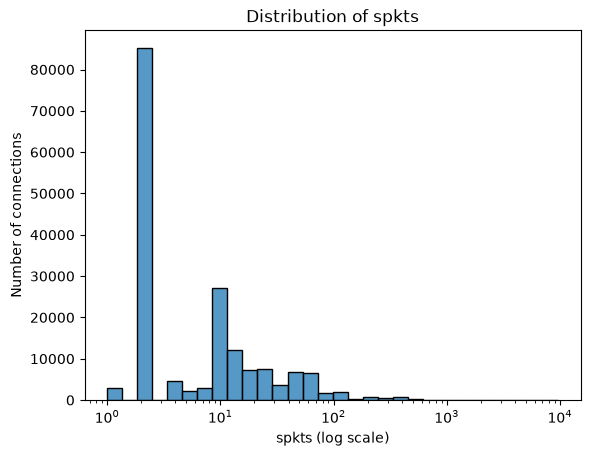

In [26]:
# Histogram of packets sent by the source (log scale)
sns.histplot(df['spkts'], bins=30, log_scale=True)
plt.title("Distribution of spkts")
plt.xlabel("spkts (log scale)")
plt.ylabel("Number of connections")
plt.show()

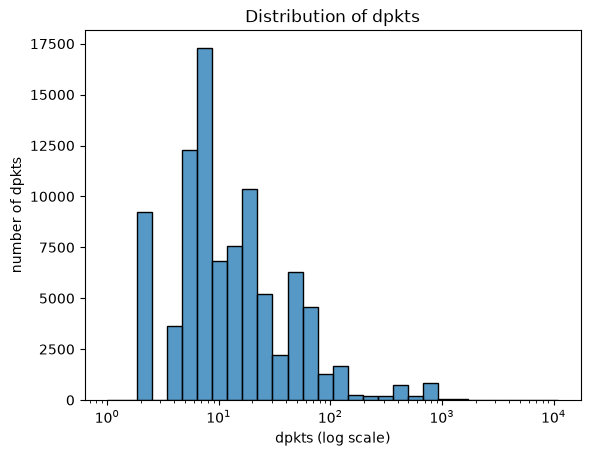

In [27]:
# Histogram of packets sent by the destination (log scale)
sns.histplot(df['dpkts'], bins=30, log_scale=True)
plt.title("Distribution of dpkts")
plt.xlabel("dpkts (log scale)")
plt.ylabel("number of dpkts")
plt.show()

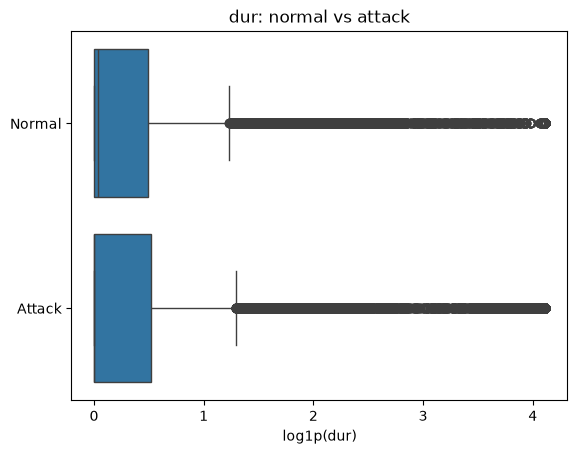

In [28]:
# Helper: box plot of one column, comparing normal and attack traffic
# log1p is used because the values are very skewed
def compare(col):
    d = df.assign(v=np.log1p(df[col]),
                  traffic=df['label'].map({0: 'Normal', 1: 'Attack'}))
    sns.boxplot(data=d, x='v', y='traffic')
    plt.title(f"{col}: normal vs attack")
    plt.xlabel(f"log1p({col})")
    plt.ylabel("")
    plt.show()

compare('dur')

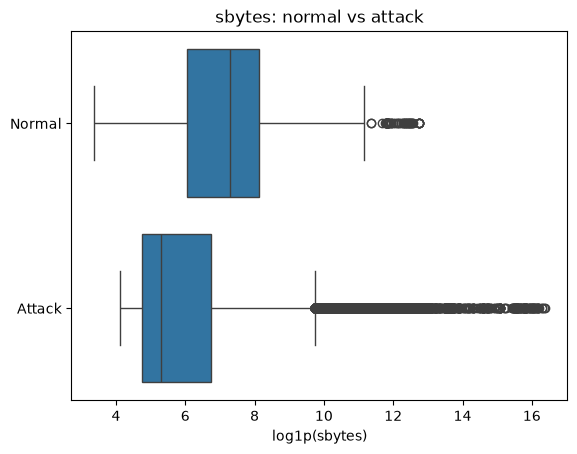

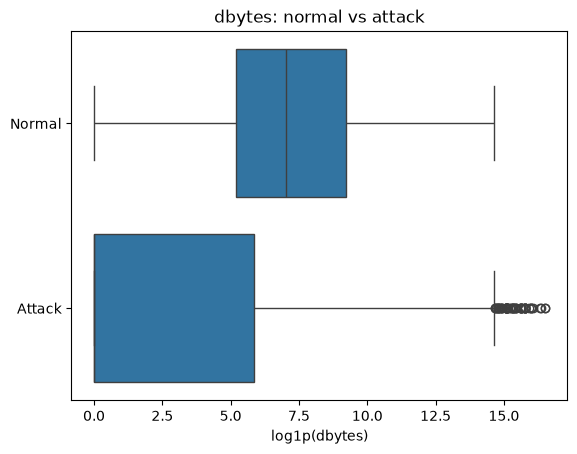

In [29]:
# Compare source and destination bytes for normal vs attack traffic
compare('sbytes')
compare('dbytes')

In [30]:
df.drop(['id','label','attack_cat'], axis=1).corr(numeric_only=True)
# df[['dur','spkts','dpkts','sbytes','dbytes']].corr()

,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,...,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports
dur,1.000000,0.254559,0.181182,0.199731,0.144134,-0.120966,0.012196,0.044159,-0.081749,-0.050603,...,-0.086300,-0.094091,-0.093923,-0.101760,0.020641,0.020641,0.024743,-0.080871,-0.115336,0.035370
spkts,0.254559,1.000000,0.390067,0.963791,0.206609,-0.076358,-0.102723,0.068246,-0.051646,0.075897,...,-0.060194,-0.068373,-0.072484,-0.077553,0.009951,0.009951,0.006084,-0.061584,-0.069598,-0.017770
dpkts,0.181182,0.390067,1.000000,0.188476,0.971907,-0.098202,-0.192580,0.053861,-0.066710,0.139145,...,-0.071909,-0.086695,-0.094267,-0.094085,0.013491,0.013491,0.047974,-0.075190,-0.078342,-0.021765
sbytes,0.199731,0.963791,0.188476,1.000000,0.009926,-0.028468,-0.020860,0.063009,-0.018322,-0.007829,...,-0.026661,-0.026490,-0.027281,-0.032061,-0.004515,-0.004515,-0.002185,-0.027479,-0.034553,-0.006367
dbytes,0.144134,0.206609,0.971907,0.009926,1.000000,-0.059475,-0.135515,0.023559,-0.040430,0.104757,...,-0.042633,-0.052135,-0.056901,-0.054633,-0.010460,-0.010460,0.051403,-0.045594,-0.044531,-0.013147
rate,-0.120966,-0.076358,-0.098202,-0.028468,-0.059475,1.000000,0.407572,-0.414546,0.602492,-0.153051,...,0.317229,0.353589,0.390721,0.383094,-0.068140,-0.068140,-0.109297,0.310876,0.362883,-0.072948
sttl,0.012196,-0.102723,-0.192580,-0.020860,-0.135515,0.407572,1.000000,-0.032823,0.276475,-0.397431,...,0.271383,0.344104,0.379930,0.404346,-0.124157,-0.124157,-0.112833,0.273252,0.340678,-0.220429
dttl,0.044159,0.068246,0.053861,0.063009,0.023559,-0.414546,-0.032823,1.000000,-0.280427,-0.116421,...,-0.381678,-0.366308,-0.389429,-0.403465,0.107208,0.107208,0.223652,-0.365404,-0.431188,-0.091137
sload,-0.081749,-0.051646,-0.066710,-0.018322,-0.040430,0.602492,0.276475,-0.280427,1.000000,-0.106294,...,0.076471,0.100118,0.082462,0.155030,-0.046194,-0.046194,-0.073920,0.084412,0.141168,-0.049327
dload,-0.050603,0.075897,0.139145,-0.007829,0.104757,-0.153051,-0.397431,-0.116421,-0.106294,1.000000,...,-0.100953,-0.143573,-0.153429,-0.161192,-0.027810,-0.027810,-0.039246,-0.098149,-0.087247,-0.035069


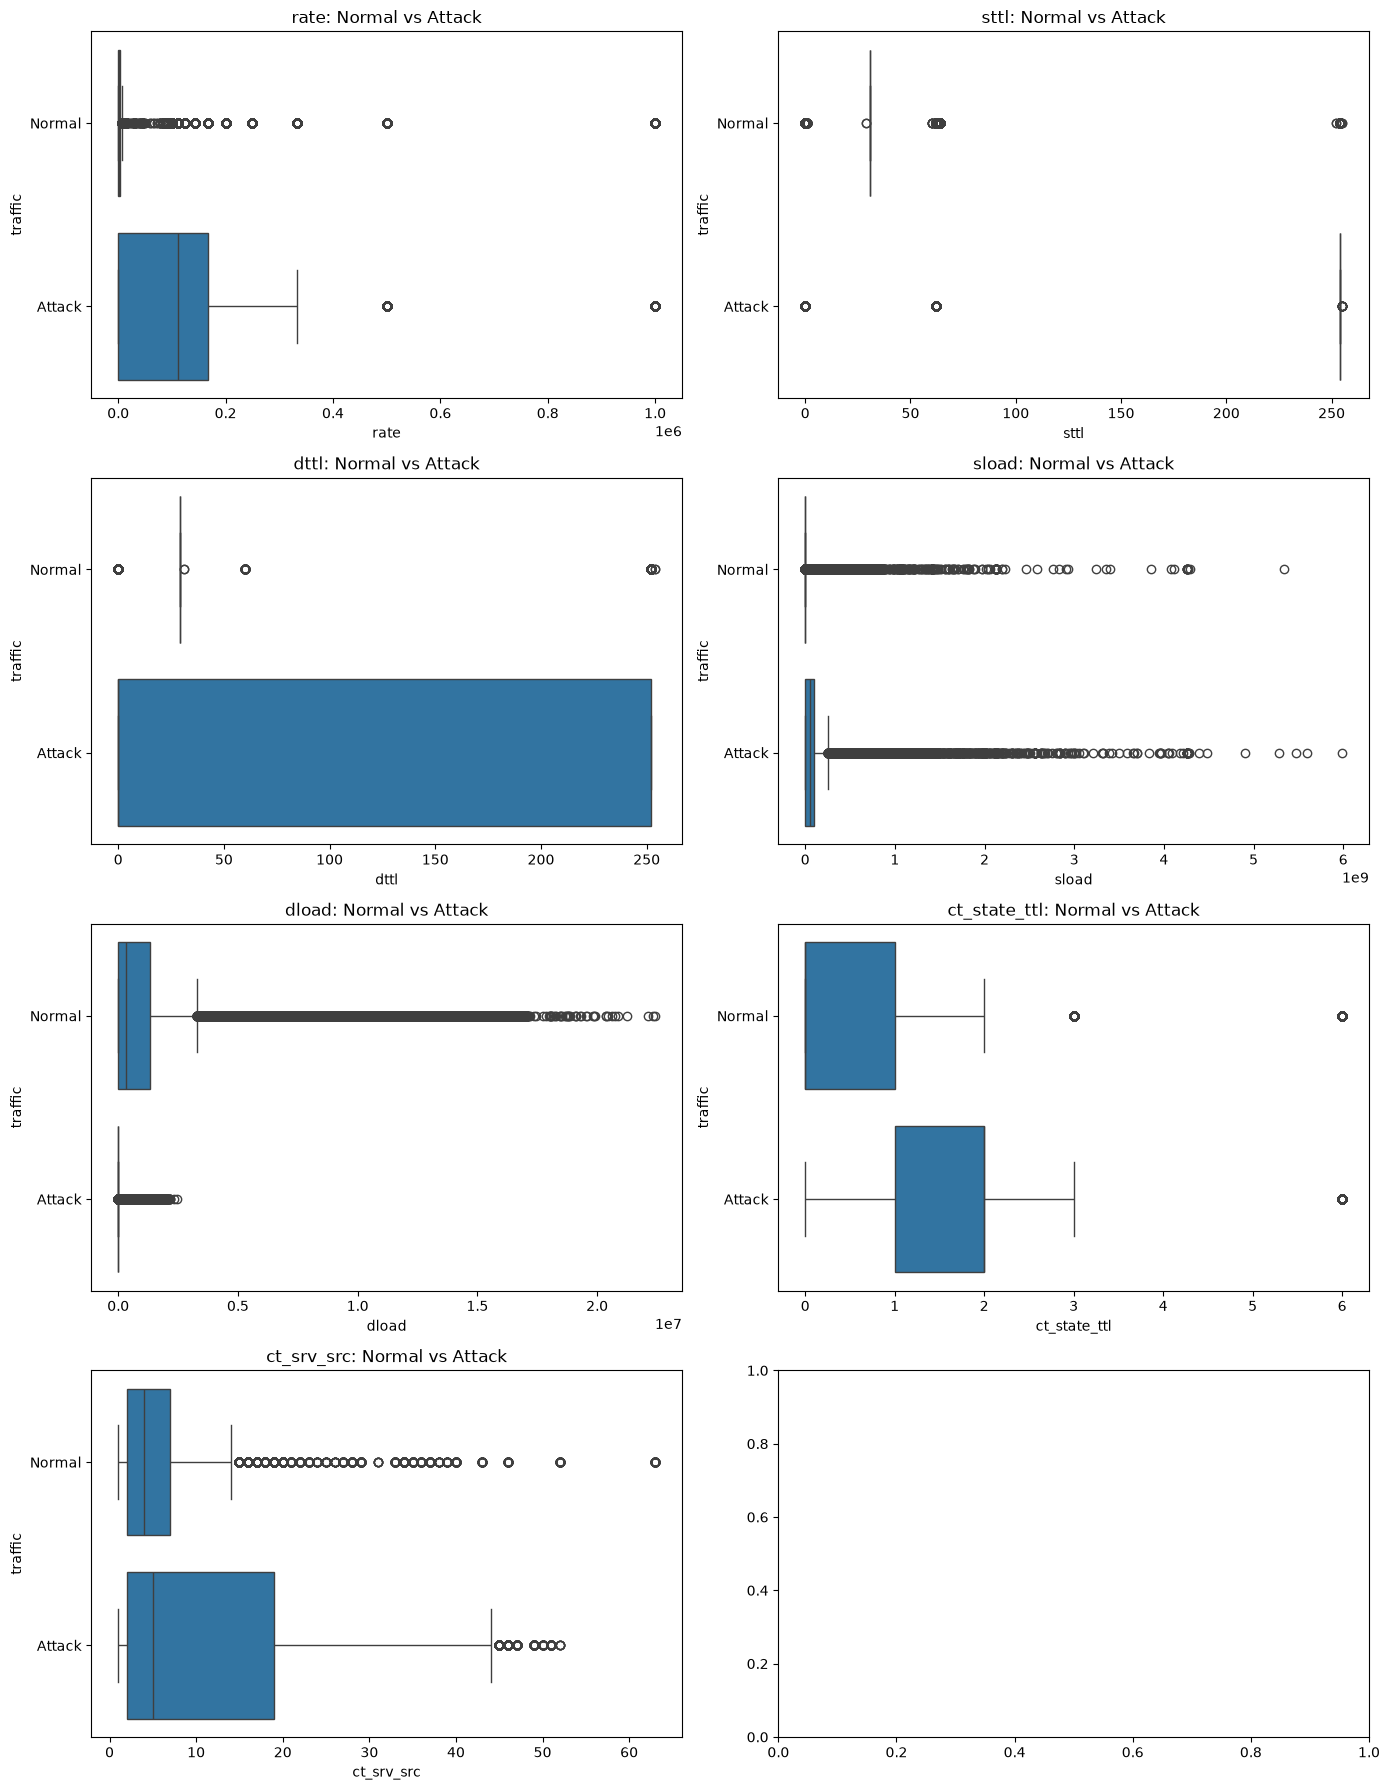

In [31]:
# Box plots of 7 important features, normal vs attack
# The grid has 8 spaces, so the last one stays empty
features = [
    "rate",
    "sttl",
    "dttl",
    "sload",
    "dload",
    "ct_state_ttl",
    "ct_srv_src"
]

traffic = df.assign(
    traffic=df["label"].map({0: "Normal", 1: "Attack"})
)

fig, axes = plt.subplots(4, 2, figsize=(14, 18))

for ax, col in zip(axes.flat, features):
    sns.boxplot(
        data=traffic,
        x=col,
        y="traffic",
        ax=ax
    )
    ax.set_title(f"{col}: Normal vs Attack")

plt.tight_layout()
plt.show()

In [32]:
# Correlation of each numerical feature with the label
# Positive = higher values mean more likely an attack
numeric_df = df.select_dtypes(include="number")

target_corr = (
    numeric_df
    .drop(columns=["id", "label"], errors="ignore")
    .corrwith(df["label"])
    .sort_values()
)

target_corr

dload               -0.393739
dmean               -0.341806
swin                -0.333633
dwin                -0.319626
stcpb               -0.255006
dtcpb               -0.250340
is_sm_ips_ports     -0.184679
sinpkt              -0.176110
dpkts               -0.118591
dloss               -0.094685
dbytes              -0.076871
djit                -0.060870
spkts               -0.052178
dinpkt              -0.022887
response_body_len   -0.021361
ct_ftp_cmd          -0.011055
is_ftp_login        -0.011055
smean               -0.010798
sjit                -0.007069
sloss               -0.000640
trans_depth          0.010801
ct_flw_http_mthd     0.015800
sbytes               0.018576
dur                  0.036175
synack               0.058299
tcprtt               0.081584
dttl                 0.095049
ackdat               0.097364
sload                0.182870
ct_srv_dst           0.228046
ct_srv_src           0.229044
ct_dst_ltm           0.229887
ct_src_ltm           0.238225
ct_dst_src

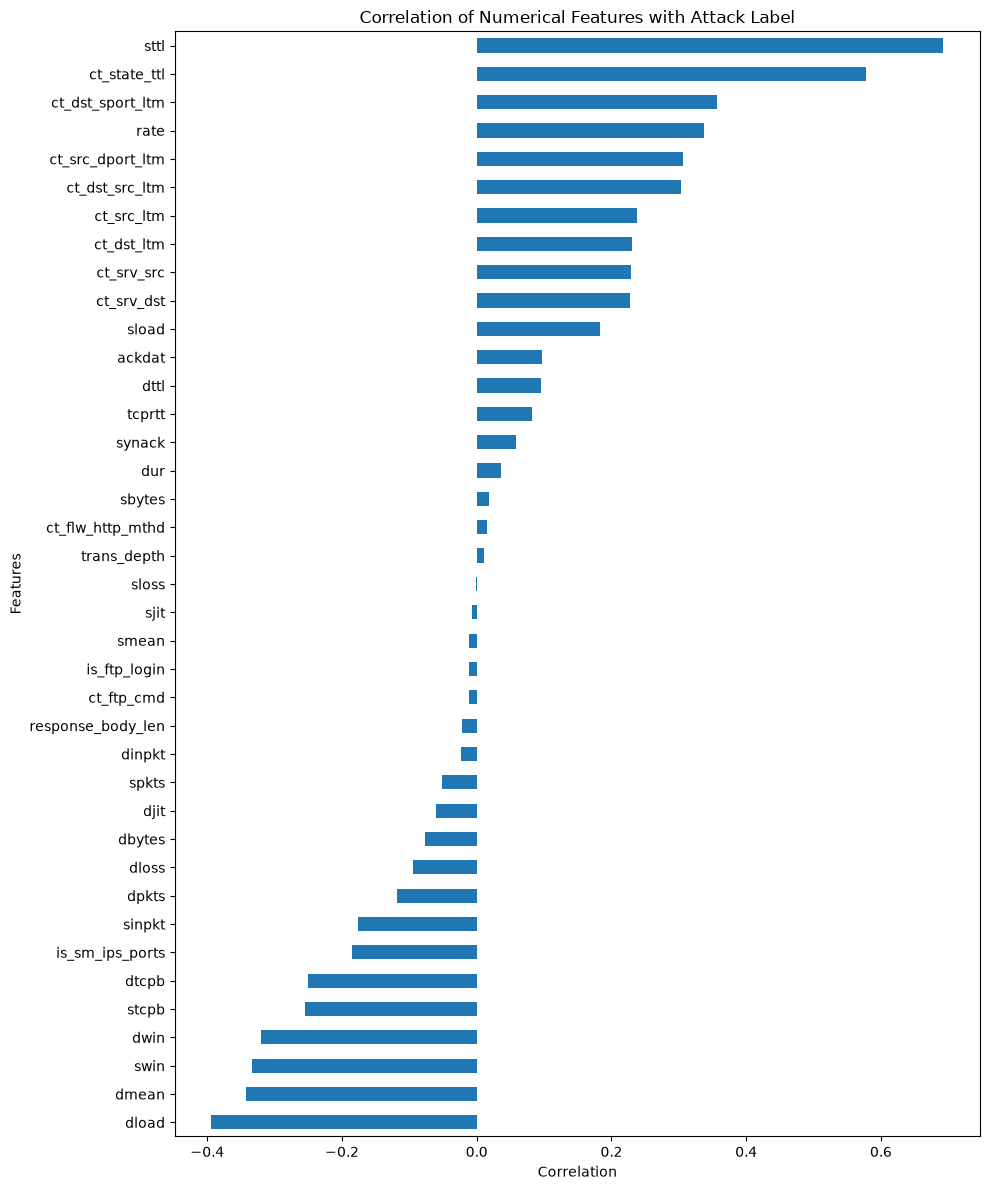

In [33]:
# Horizontal bar chart of the correlations above
plt.figure(figsize=(10, 12))

target_corr.plot(kind="barh")

plt.title("Correlation of Numerical Features with Attack Label")
plt.xlabel("Correlation")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

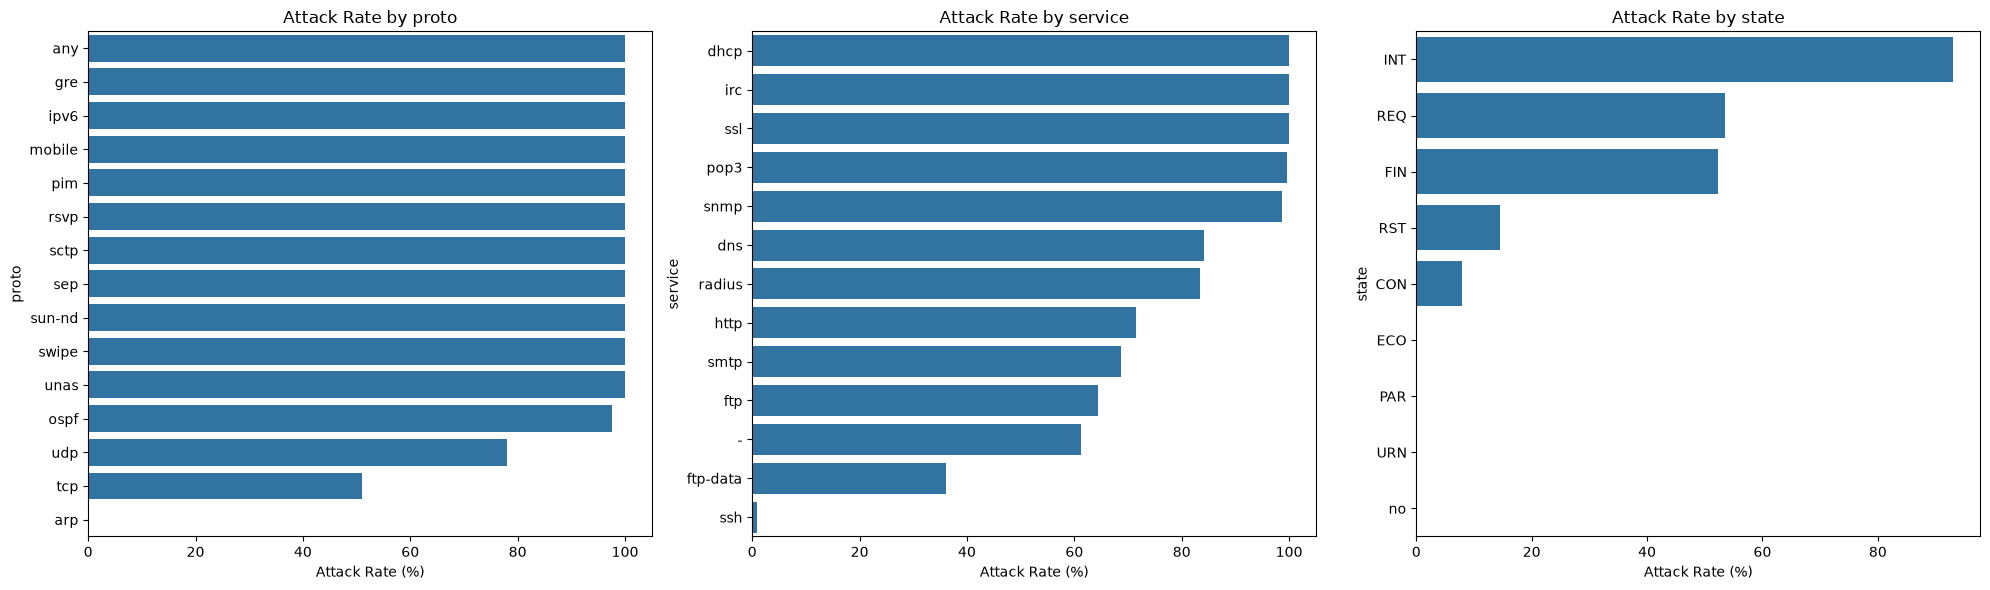

In [34]:
categorical_features = ["proto", "service", "state"]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, col in zip(axes, categorical_features):

    # Select the 15 most frequent categories
    top_categories = df[col].value_counts().head(15).index

    # Calculate attack rate for each category
    attack_rate = (
        df[df[col].isin(top_categories)]
        .groupby(col)["label"]
        .mean()
        .sort_values(ascending=False)
        * 100
    )

    sns.barplot(
        x=attack_rate.values,
        y=attack_rate.index,
        ax=ax
    )

    ax.set_title(f"Attack Rate by {col}")
    ax.set_xlabel("Attack Rate (%)")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

In [35]:
# Dataset overview
print("Dataset shape:", df.shape)

# Data types
print(df.dtypes)

# Categorical columns
categorical_cols = df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("\nCategorical columns:")
print(categorical_cols)

# Unique values in each categorical column
for col in categorical_cols:
    print(f"\n{col}: {df[col].nunique()} unique values")

Dataset shape: (175341, 45)
id                     int64
dur                  float64
proto                    str
service                  str
state                    str
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             int64
ct_state_ttl           int64
ct_dst_ltm     

In [36]:
# Target variable
y = df["label"]

# Input features
X = df.drop(
    columns=["id", "label", "attack_cat"]
)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (175341, 42)
y shape: (175341,)

Target distribution:
label
1    119341
0     56000
Name: count, dtype: int64


In [37]:
# Save a copy of the data to a new CSV file
# Note: no rows or columns have been changed yet, so it is the same as the raw data
df.to_csv(
    "unsw_nb15_cleaned.csv",
    index=False
)

In [38]:
# Split the feature columns into text (categorical) and number (numerical) columns
categorical_cols = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", categorical_cols)
print("Number of categorical features:", len(categorical_cols))

print("\nNumerical features:", numerical_cols)
print("Number of numerical features:", len(numerical_cols))

Categorical features: ['proto', 'service', 'state']
Number of categorical features: 3

Numerical features: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']
Number of numerical features: 39


In [39]:
# Create a copy of our feature dataset
X_encoded = X.copy()

# Apply One-Hot Encoding
X_encoded = pd.get_dummies(
    X_encoded,
    columns=categorical_cols,
    dtype=int
)

# Inspect the result
print("Original shape:", X.shape)
print("Encoded shape:", X_encoded.shape)

print("\nFirst five rows:")
display(X_encoded.head())

Original shape: (175341, 42)
Encoded shape: (175341, 194)

First five rows:


,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,...,service_ssl,state_CON,state_ECO,state_FIN,state_INT,state_PAR,state_REQ,state_RST,state_URN,state_no
0,0.121478,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,...,0,0,0,1,0,0,0,0,0,0
1,0.649902,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,...,0,0,0,1,0,0,0,0,0,0
2,1.623129,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,...,0,0,0,1,0,0,0,0,0,0
3,1.681642,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,...,0,0,0,1,0,0,0,0,0,0
4,0.449454,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,...,0,0,0,1,0,0,0,0,0,0


In [40]:
# Check that no text columns are left after one-hot encoding
print("Remaining categorical columns:")
print(
    X_encoded.select_dtypes(
        include=["object", "category", "string"]
    ).columns.tolist()
)

print("\nTotal features after encoding:", X_encoded.shape[1])

Remaining categorical columns:
[]

Total features after encoding: 194


In [41]:
# Summary statistics for numerical features
X[numerical_cols].describe().T[
    ["mean", "std", "min", "25%", "50%", "75%", "max"]
].style.format('{:,.6f}')

,mean,std,min,25%,50%,75%,max
dur,1.359389,6.480249,0.000000,0.000008,0.001582,0.668069,59.999989
spkts,20.298664,136.887597,1.000000,2.000000,2.000000,12.000000,"9,616.000000"
dpkts,18.969591,110.258271,0.000000,0.000000,2.000000,10.000000,"10,974.000000"
sbytes,"8,844.843836","174,765.644309",28.000000,114.000000,430.000000,"1,418.000000","12,965,233.000000"
dbytes,"14,928.918564","143,654.217718",0.000000,0.000000,164.000000,"1,102.000000","14,655,550.000000"
rate,"95,406.187105","165,400.978457",0.000000,32.786140,"3,225.806520","125,000.000300","1,000,000.003000"
sttl,179.546997,102.940011,0.000000,62.000000,254.000000,254.000000,255.000000
dttl,79.609567,110.506863,0.000000,0.000000,29.000000,252.000000,254.000000
sload,"73,454,033.194063","188,357,447.000203",0.000000,"13,053.338870","879,674.750000","88,888,888.000000","5,988,000,256.000000"
dload,"671,205.574188","2,421,312.388757",0.000000,0.000000,"1,447.022705","27,844.871090","22,422,730.000000"


In [42]:
#Calculate skewness
skew_values = X[numerical_cols].skew()
skew_values

dur                    7.496061
spkts                 40.217703
dpkts                 36.764114
sbytes                45.303443
dbytes                39.760864
rate                   3.319495
sttl                  -0.678109
dttl                   0.895010
sload                  8.703399
dload                  4.691217
sloss                 44.753662
dloss                 41.380270
sinpkt                 7.917535
dinpkt                29.679512
sjit                  17.652157
djit                  29.543830
swin                   0.177048
stcpb                  1.081121
dtcpb                  1.081017
dwin                   0.196820
tcprtt                 4.038359
synack                 5.786286
ackdat                 5.615605
smean                  3.726623
dmean                  2.826146
trans_depth          167.335829
response_body_len     76.340075
ct_srv_src             1.521178
ct_state_ttl           0.928414
ct_dst_ltm             2.050110
ct_src_dport_ltm       2.171187
ct_dst_s

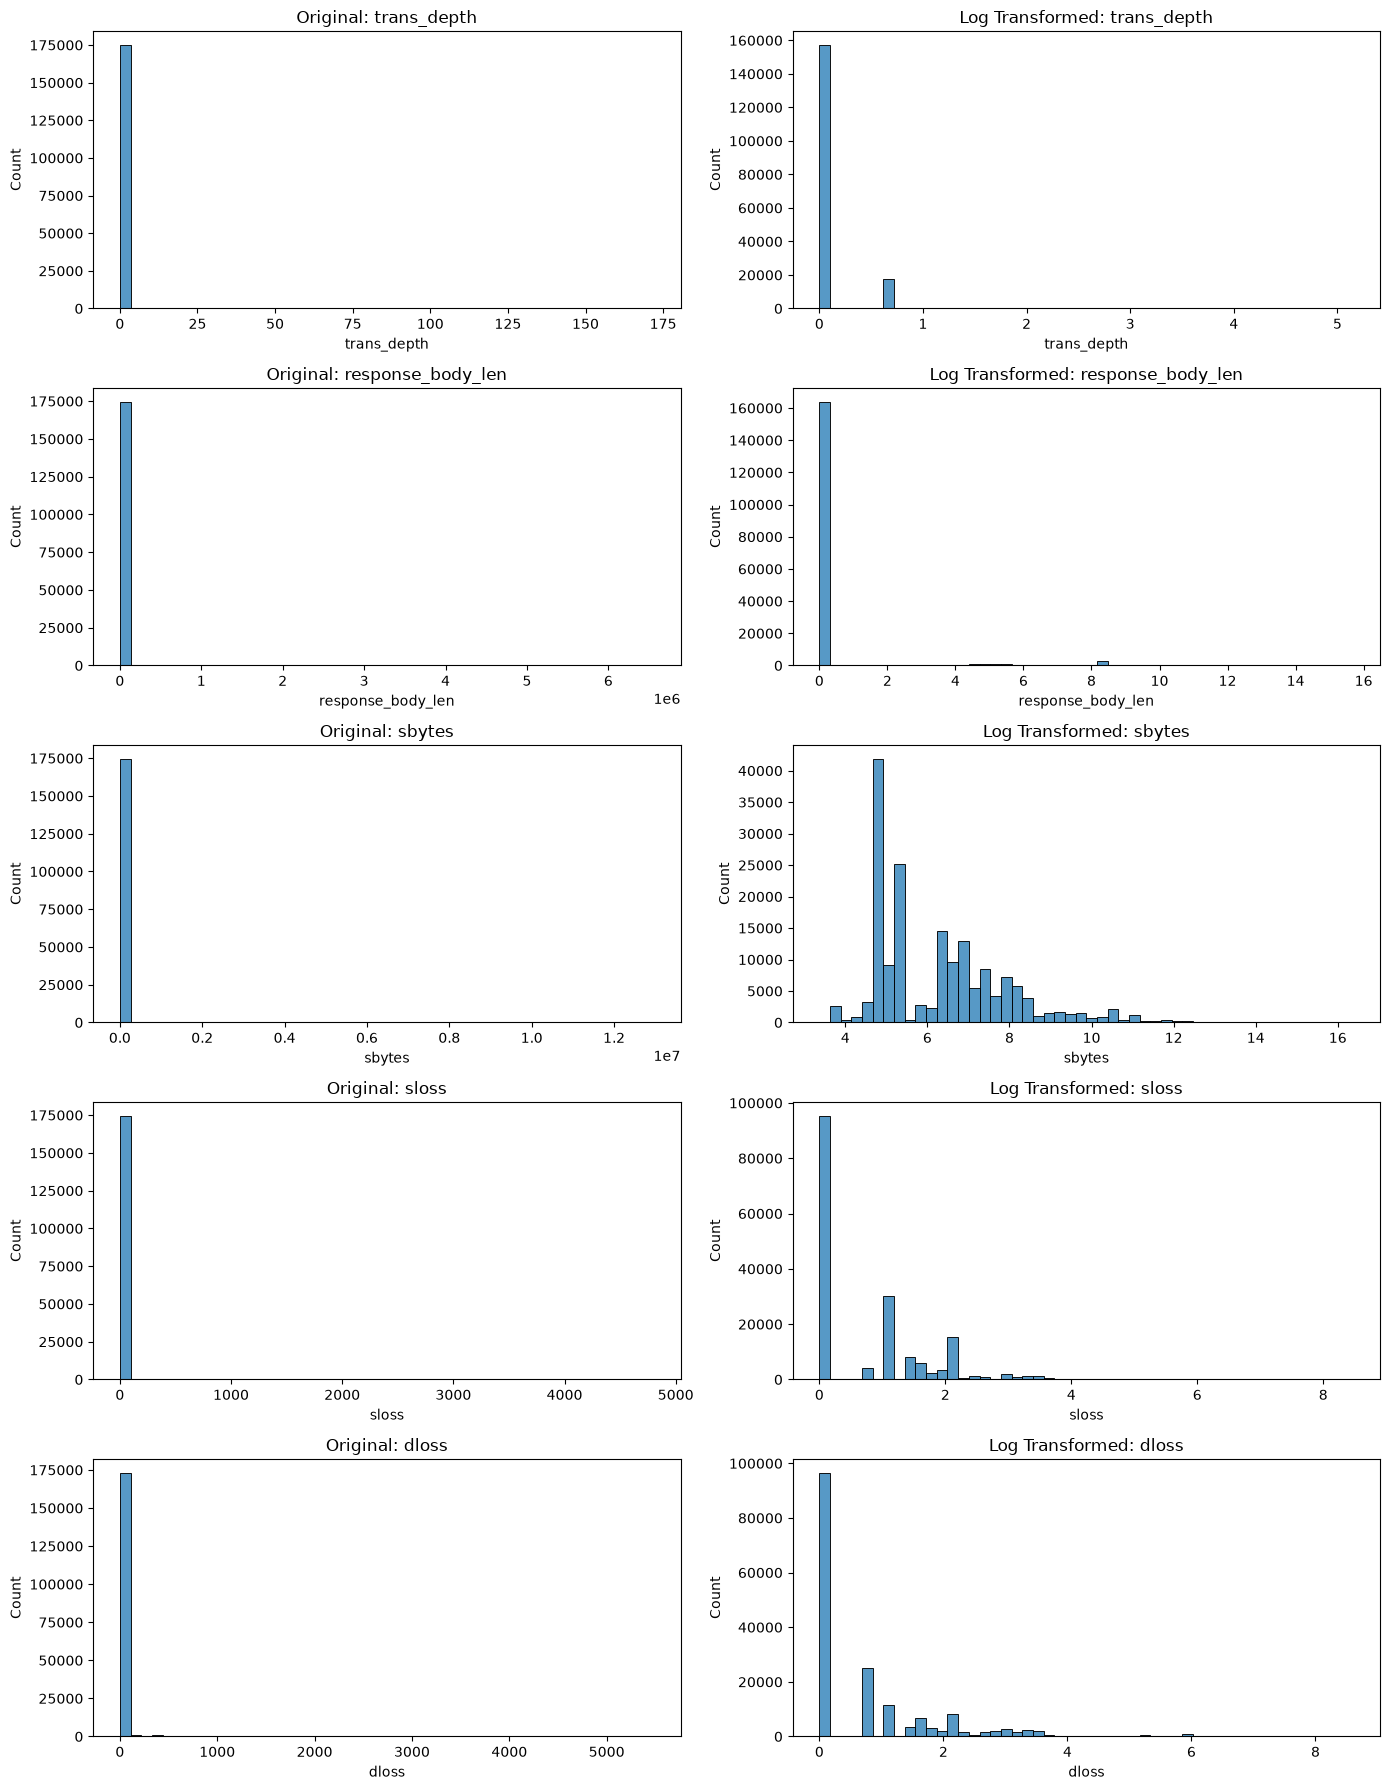

In [43]:
skewed_features = [
    "trans_depth",
    "response_body_len",
    "sbytes",
    "sloss",
    "dloss"
]
fig, axes = plt.subplots( len(skewed_features), 2, figsize= (14,18))
for i, col in enumerate(skewed_features):
    # original distribution (without log)
    sns.histplot(X[col], bins=50, ax=axes[i,0])
    axes[i,0].set_title(f"Original: {col}")
    
    # Log-transformed distribution
    sns.histplot(np.log1p(X[col]), bins=50, ax=axes[i, 1])
    axes[i, 1].set_title(f"Log Transformed: {col}")

plt.tight_layout()
plt.show()

In [44]:
# Compare skewness before and after the log1p transform
# Values closer to 0 mean a more balanced shape
log_skewness = X[skewed_features].apply(
    lambda col: np.log1p(col).skew()
)

comparison = pd.DataFrame({
    "Original Skewness": X[skewed_features].skew(),
    "Log Skewness": log_skewness
})

comparison

,Original Skewness,Log Skewness
trans_depth,167.335829,2.924598
response_body_len,76.340075,4.168025
sbytes,45.303443,1.169003
sloss,44.753662,1.376688
dloss,41.380270,1.786355


In [45]:
# Columns with skewness above 1 or below -1 (highly skewed)
highly_skewed = skew_values[ skew_values.abs() > 1 ].sort_values(ascending=False)
print(f"Number of highly skewed values: {len(highly_skewed)}")
highly_skewed

Number of highly skewed values: 34


trans_depth          167.335829
response_body_len     76.340075
sbytes                45.303443
sloss                 44.753662
dloss                 41.380270
spkts                 40.217703
dbytes                39.760864
dpkts                 36.764114
dinpkt                29.679512
djit                  29.543830
ct_flw_http_mthd      23.451424
sjit                  17.652157
ct_ftp_cmd             9.943196
is_ftp_login           9.943196
sload                  8.703399
sinpkt                 7.917535
is_sm_ips_ports        7.778199
dur                    7.496061
synack                 5.786286
ackdat                 5.615605
dload                  4.691217
tcprtt                 4.038359
smean                  3.726623
rate                   3.319495
dmean                  2.826146
ct_src_dport_ltm       2.171187
ct_dst_ltm             2.050110
ct_src_ltm             1.842085
ct_dst_sport_ltm       1.696466
ct_dst_src_ltm         1.555365
ct_srv_dst             1.529025
ct_srv_s

In [46]:
# Numerical columns that only have 2 different values (yes/no style)
binary_cols = [ col for col in numerical_cols if X[col].nunique() == 2]
binary_cols

['is_sm_ips_ports']

In [47]:
# Numerical columns with 10 or fewer different values
low_cardinality_cols = [col for col in numerical_cols if X[col].nunique() <= 10 ]
low_cardinality_cols

['dttl',
 'dwin',
 'ct_state_ttl',
 'is_ftp_login',
 'ct_ftp_cmd',
 'is_sm_ips_ports']

In [48]:
# Split the data: 80% for training, 20% for testing
# stratify=y keeps the same normal/attack ratio in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (140272, 42)
Testing features: (35069, 42)

Training target distribution:
label
1    68.062051
0    31.937949
Name: proportion, dtype: float64

Testing target distribution:
label
1    68.062962
0    31.937038
Name: proportion, dtype: float64


In [49]:
# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine both transformers
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

In [50]:
# Learn the scaling and encoding from the training data only,
# then apply the same steps to the test data
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (140272, 192)
Testing shape: (35069, 192)


In [51]:
# Baseline model: Logistic Regression
# class_weight="balanced" stops the model from favouring the bigger class
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_processed, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [52]:
# Predict on the test data and show the first 20 predictions (0 = normal, 1 = attack)
y_pred = model.predict(X_test_processed)

print(y_pred[:20])

[1 1 1 1 1 1 1 1 1 1 0 1 1 0 1 1 1 1 1 1]


In [53]:
# Score the predictions
# Precision: of the rows we called attacks, how many really were attacks
# Recall: of the real attacks, how many we caught
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9328181584875531
Precision: 0.950345405065941
Recall: 0.950982445850266
F1 Score: 0.9506638187376973

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.89      0.89     11200
           1       0.95      0.95      0.95     23869

    accuracy                           0.93     35069
   macro avg       0.92      0.92      0.92     35069
weighted avg       0.93      0.93      0.93     35069



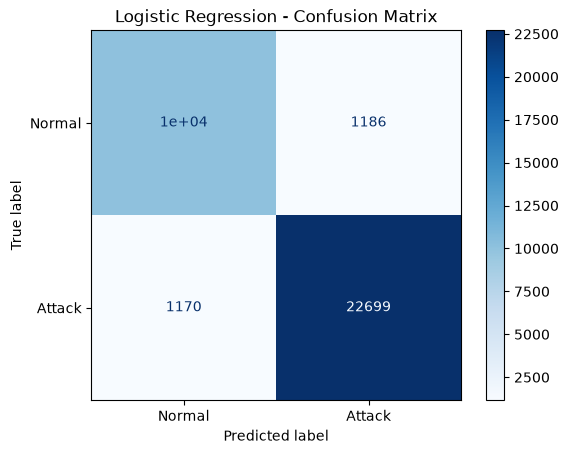

In [54]:
# Confusion matrix: correct and wrong predictions for each class
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [55]:
# Combine preprocessing and model
baseline_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", model)
])

# Save the pipeline
joblib.dump(
    baseline_pipeline,
    "logistic_regression_baseline.pkl"
)

['logistic_regression_baseline.pkl']

In [56]:
# ---------------- Step 1: Load the official test set ----------------
# UNSW-NB15 comes with a separate test file that the model has never seen.
# Testing on it shows how well the model works on new traffic.
official_df = pd.read_csv("UNSW_NB15_testing-set.csv")

# Separate the inputs (X) and the answers (y), the same way as for training
X_official = official_df.drop(columns=["id", "label", "attack_cat"])
y_official = official_df["label"]

print("Official test shape:", X_official.shape)
print("\nTarget distribution:")
print(y_official.value_counts())

Official test shape: (82332, 42)

Target distribution:
label
1    45332
0    37000
Name: count, dtype: int64


In [57]:
# Helper that scores a model and returns the results.
# We use it for every model so the comparison is fair.
def evaluate(model, X_data, y_true):
    y_hat = model.predict(X_data)
    return {
        "Accuracy": accuracy_score(y_true, y_hat),
        "Precision": precision_score(y_true, y_hat),
        "Recall": recall_score(y_true, y_hat),
        "F1 Score": f1_score(y_true, y_hat),
    }

# How does the baseline do on the official test set?
# A big drop here means the official data is harder (it has traffic patterns the training file does not)
pd.DataFrame({
    "Our test split": evaluate(baseline_pipeline, X_test, y_test),
    "Official test set": evaluate(baseline_pipeline, X_official, y_official),
}).round(4)

,Our test split,Official test set
Accuracy,0.9328,0.8358
Precision,0.9503,0.8031
Recall,0.9510,0.9298
F1 Score,0.9507,0.8618


In [58]:
# ---------------- Step 2: Add the log transform to the pipeline ----------------
# Earlier we found many highly skewed columns (skewness above 1).
# log1p pulls very large values closer together, which helps Logistic Regression.
# All values are 0 or more, so log1p is safe to use.
log_cols = highly_skewed.index.tolist()

# The other numerical columns only get scaled
plain_cols = [col for col in numerical_cols if col not in log_cols]

print("Columns that get the log transform:", len(log_cols))
print("Columns that are only scaled:", len(plain_cols))

log_preprocessor = ColumnTransformer(
    transformers=[
        ("log", Pipeline([
            ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("scale", StandardScaler())
        ]), log_cols),
        ("num", StandardScaler(), plain_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

Columns that get the log transform: 34
Columns that are only scaled: 5


In [59]:
# Train Logistic Regression again, this time with the log transform.
# The pipeline does the preprocessing and the training in one step.
log_lr_pipeline = Pipeline([
    ("preprocessor", log_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

log_lr_pipeline.fit(X_train, y_train)

pd.DataFrame({
    "Our test split": evaluate(log_lr_pipeline, X_test, y_test),
    "Official test set": evaluate(log_lr_pipeline, X_official, y_official),
}).round(4)

,Our test split,Official test set
Accuracy,0.9341,0.8685
Precision,0.9631,0.8404
Recall,0.9392,0.9396
F1 Score,0.9510,0.8872


In [60]:
# ---------------- Step 3: Try tree-based models ----------------
# Tree models split the data with simple "greater than / less than" rules,
# so they do not need scaling or log transforms.
# We only turn the text columns (proto, service, state) into numbers.
tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols)
    ]
)

# Random Forest: many decision trees vote together on the answer
rf_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,      # number of trees
        min_samples_leaf=2,    # each leaf needs at least 2 rows (reduces overfitting)
        n_jobs=-1,             # use all CPU cores
        random_state=42
    ))
])

rf_pipeline.fit(X_train, y_train)

pd.DataFrame({
    "Our test split": evaluate(rf_pipeline, X_test, y_test),
    "Official test set": evaluate(rf_pipeline, X_official, y_official),
}).round(4)

,Our test split,Official test set
Accuracy,0.9601,0.8672
Precision,0.9609,0.8112
Recall,0.9814,0.9891
F1 Score,0.9710,0.8913


In [61]:
# Gradient Boosting: builds trees one after another,
# and each new tree tries to fix the mistakes of the trees before it.
hgb_pipeline = Pipeline([
    # clone() makes a fresh copy, so the Random Forest's preprocessor is not touched
    ("preprocessor", clone(tree_preprocessor)),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=300,          # number of trees
        random_state=42
    ))
])

hgb_pipeline.fit(X_train, y_train)

pd.DataFrame({
    "Our test split": evaluate(hgb_pipeline, X_test, y_test),
    "Official test set": evaluate(hgb_pipeline, X_official, y_official),
}).round(4)

,Our test split,Official test set
Accuracy,0.9589,0.8711
Precision,0.9633,0.8203
Recall,0.9769,0.9807
F1 Score,0.9700,0.8934


In [62]:
# ---------------- Step 4: Compare all models ----------------
models = {
    "Logistic Regression (baseline)": baseline_pipeline,
    "Logistic Regression + log": log_lr_pipeline,
    "Random Forest": rf_pipeline,
    "Gradient Boosting": hgb_pipeline,
}

# Score every model on both test sets
split_scores = pd.DataFrame(
    {name: evaluate(m, X_test, y_test) for name, m in models.items()}
).T
official_scores = pd.DataFrame(
    {name: evaluate(m, X_official, y_official) for name, m in models.items()}
).T

print("Scores on our test split:")
display(split_scores.round(4))

print("\nScores on the official test set:")
display(official_scores.round(4))

Scores on our test split:


,Accuracy,Precision,Recall,F1 Score
Logistic Regression (baseline),0.9328,0.9503,0.9510,0.9507
Logistic Regression + log,0.9341,0.9631,0.9392,0.9510
Random Forest,0.9601,0.9609,0.9814,0.9710
Gradient Boosting,0.9589,0.9633,0.9769,0.9700



Scores on the official test set:


,Accuracy,Precision,Recall,F1 Score
Logistic Regression (baseline),0.8358,0.8031,0.9298,0.8618
Logistic Regression + log,0.8685,0.8404,0.9396,0.8872
Random Forest,0.8672,0.8112,0.9891,0.8913
Gradient Boosting,0.8711,0.8203,0.9807,0.8934


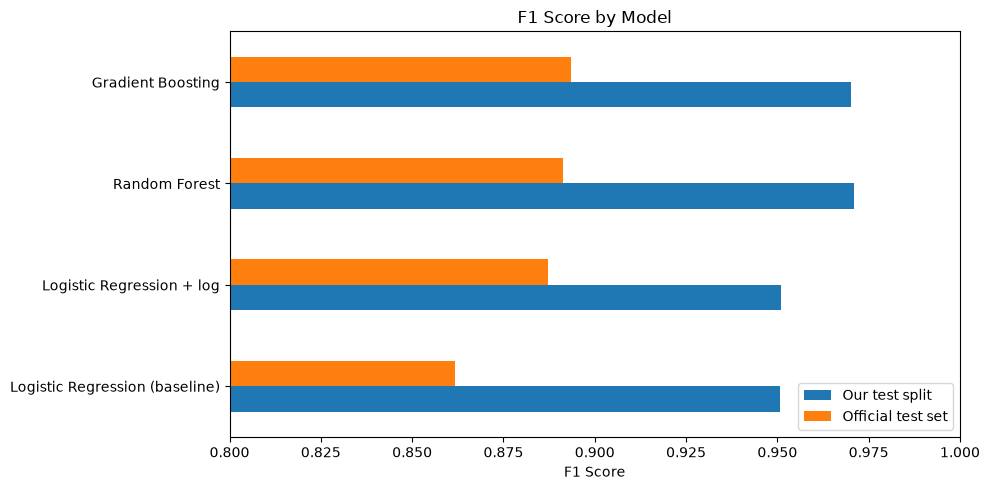

In [63]:
# Bar chart of the F1 score of each model on both test sets
f1_compare = pd.DataFrame({
    "Our test split": split_scores["F1 Score"],
    "Official test set": official_scores["F1 Score"],
})

f1_compare.plot(kind="barh", figsize=(10, 5))
plt.title("F1 Score by Model")
plt.xlabel("F1 Score")
plt.xlim(0.8, 1.0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [64]:
# Pick the best model using OUR test split only.
# The official test set is kept for the final check, so we do not "cheat"
# by choosing whichever model happens to score best on it.
best_name = split_scores["F1 Score"].idxmax()
best_model = models[best_name]
print("Best model:", best_name)

# Detailed report of the best model on the official test set
y_official_pred = best_model.predict(X_official)
print(classification_report(
    y_official,
    y_official_pred,
    target_names=["Normal", "Attack"]
))

Best model: Random Forest


              precision    recall  f1-score   support

      Normal       0.98      0.72      0.83     37000
      Attack       0.81      0.99      0.89     45332

    accuracy                           0.87     82332
   macro avg       0.90      0.85      0.86     82332
weighted avg       0.89      0.87      0.86     82332



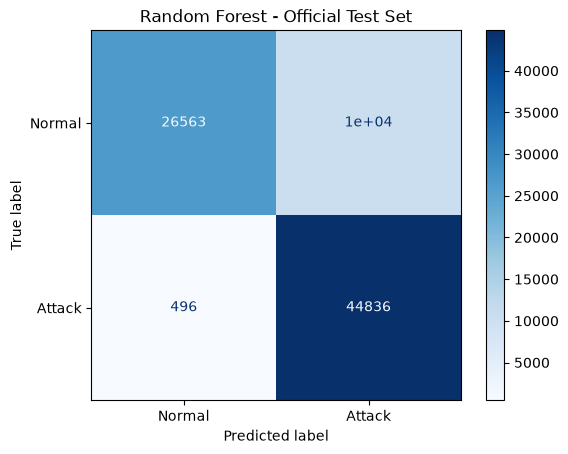

In [65]:
# Confusion matrix of the best model on the official test set
ConfusionMatrixDisplay.from_predictions(
    y_official,
    y_official_pred,
    display_labels=["Normal", "Attack"],
    cmap="Blues"
)
plt.title(f"{best_name} - Official Test Set")
plt.show()

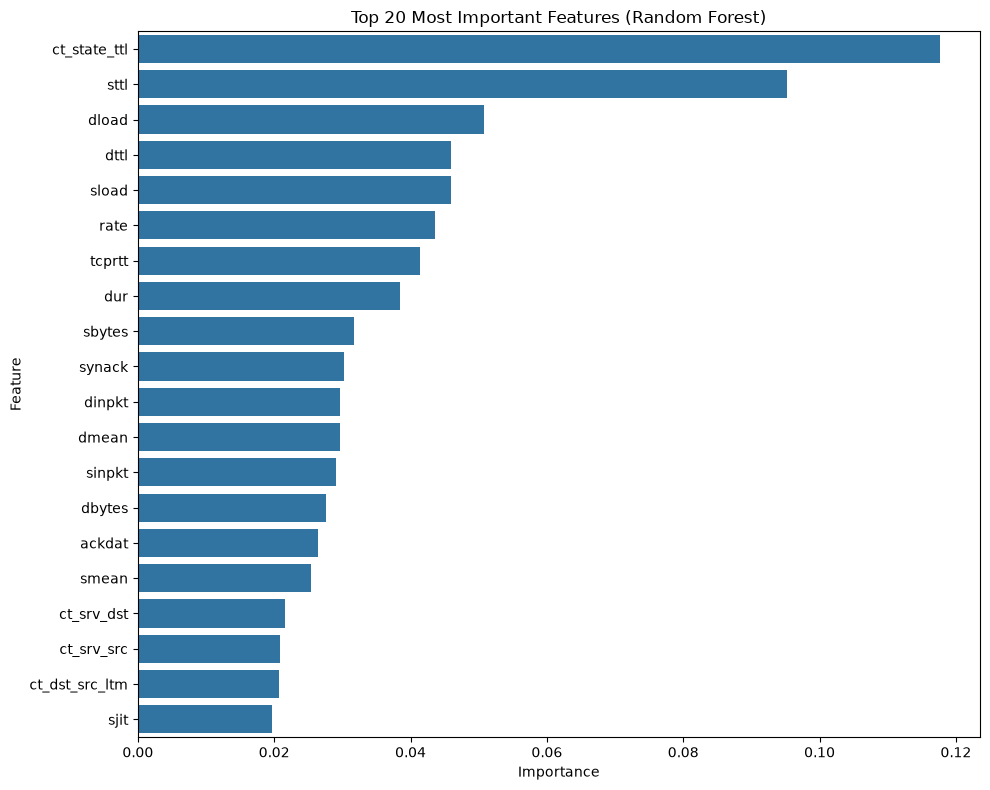

In [66]:
# ---------------- Step 5: Which features matter most? ----------------
# Random Forest tells us how much each feature helped it make decisions.
feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()

# Remove the "num__" / "cat__" prefixes so the names are easier to read
feature_names = [name.split("__", 1)[1] for name in feature_names]

importances = pd.Series(
    rf_pipeline.named_steps["classifier"].feature_importances_,
    index=feature_names
).sort_values(ascending=False)

# Show the 20 most important features
top_features = importances.head(20)

plt.figure(figsize=(10, 8))
sns.barplot(x=top_features.values, y=top_features.index)
plt.title("Top 20 Most Important Features (Random Forest)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [67]:
# ---------------- Step 6: Attack type model ----------------
# The model above only answers "attack or normal?".
# This second model answers "what kind of attack is it?".
# It is trained only on attack rows, so it can focus on telling attacks apart.
attack_rows = df["label"] == 1
X_attack = X[attack_rows]
y_attack = df.loc[attack_rows, "attack_cat"]

# The same for the official test set
official_attack_rows = official_df["label"] == 1
X_official_attack = X_official[official_attack_rows]
y_official_attack = official_df.loc[official_attack_rows, "attack_cat"]

print("Attack rows for training:", X_attack.shape[0])
print("Attack rows in the official test set:", X_official_attack.shape[0])
print("\nAttack types in the training data:")
print(y_attack.value_counts())

Attack rows for training: 119341
Attack rows in the official test set: 45332

Attack types in the training data:
attack_cat
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [68]:
# Random Forest for the attack type.
# class_weight="balanced_subsample" gives rare attacks (like Worms) more weight,
# so the model does not ignore them.
attack_type_pipeline = Pipeline([
    ("preprocessor", clone(tree_preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    ))
])

attack_type_pipeline.fit(X_attack, y_attack)

# Check it on the attack rows of the official test set
y_attack_pred = attack_type_pipeline.predict(X_official_attack)

print("Accuracy:", accuracy_score(y_official_attack, y_attack_pred))
print("\nClassification Report:")
print(classification_report(y_official_attack, y_attack_pred, zero_division=0))

Accuracy: 0.7569928527309627

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.01      0.00      0.01       677
      Backdoor       0.04      0.32      0.06       583
           DoS       0.31      0.21      0.25      4089
      Exploits       0.82      0.64      0.72     11132
       Fuzzers       0.81      0.78      0.79      6062
       Generic       1.00      0.96      0.98     18871
Reconnaissance       0.88      0.83      0.86      3496
     Shellcode       0.34      0.84      0.48       378
         Worms       0.66      0.48      0.55        44

      accuracy                           0.76     45332
     macro avg       0.54      0.56      0.52     45332
  weighted avg       0.83      0.76      0.79     45332



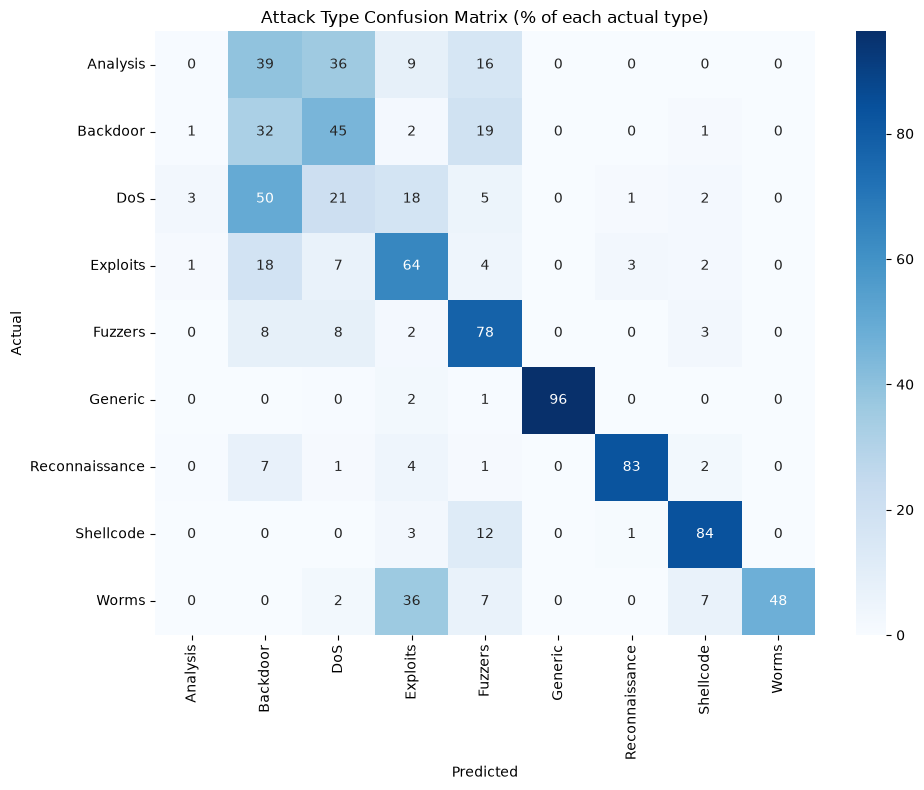

In [69]:
# Confusion matrix in percent: each row shows where that attack type ended up.
# Numbers on the diagonal are correct predictions.
attack_labels = sorted(y_attack.unique())

cm_attack = confusion_matrix(
    y_official_attack,
    y_attack_pred,
    labels=attack_labels,
    normalize="true"
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_attack * 100,
    annot=True,
    fmt=".0f",
    xticklabels=attack_labels,
    yticklabels=attack_labels,
    cmap="Blues"
)
plt.title("Attack Type Confusion Matrix (% of each actual type)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [70]:
# ---------------- Step 7: Risk score and response advice ----------------
# Risk score = how sure the model is that a connection is an attack, from 0 to 100.
# The score is turned into a simple level.
def risk_level(score):
    if score < 30:
        return "Low"
    elif score < 60:
        return "Medium"
    elif score < 85:
        return "High"
    return "Critical"

# What to do for each attack type, in simple steps
response_actions = {
    "Generic": "Block the source IP and check the targeted service for weaknesses",
    "Exploits": "Isolate the targeted host, patch the vulnerable software, check for compromise",
    "Fuzzers": "Rate-limit or block the source IP and check application logs for crashes",
    "DoS": "Turn on rate limiting, block the source IP, contact the ISP if traffic keeps growing",
    "Reconnaissance": "Block the scanning IP and close ports or services that are not needed",
    "Analysis": "Watch the source closely and review firewall and IDS rules",
    "Backdoor": "Isolate the host now, remove the backdoor, and reset passwords",
    "Shellcode": "Isolate the host, stop suspicious processes, and patch the exploited software",
    "Worms": "Isolate infected hosts, block the spreading port, and scan the whole network",
}

In [71]:
# This function puts everything together for new connections:
# 1. Is it an attack?  2. What type?  3. How risky?  4. What should we do?
def analyze_traffic(rows):
    attack_prob = best_model.predict_proba(rows)[:, 1]
    is_attack = attack_prob >= 0.5
    attack_type = attack_type_pipeline.predict(rows)

    results = pd.DataFrame(index=rows.index)
    results["Prediction"] = np.where(is_attack, "Attack", "Normal")
    results["Attack Type"] = np.where(is_attack, attack_type, "-")
    results["Risk Score"] = (attack_prob * 100).round(1)
    results["Risk Level"] = results["Risk Score"].apply(risk_level)
    results["Recommended Action"] = (
        results["Attack Type"].map(response_actions).fillna("No action needed")
    )
    return results

# Try it on 10 random connections from the official test set
sample = X_official.sample(10, random_state=42)
sample_results = analyze_traffic(sample)

# Add the real answers so we can compare
sample_results["Actual"] = official_df.loc[sample.index, "attack_cat"]
sample_results

,Prediction,Attack Type,Risk Score,Risk Level,Recommended Action,Actual
38666,Normal,-,0.4,Low,No action needed,Normal
56460,Attack,Generic,99.5,Critical,Block the source IP and check the targeted ser...,Generic
16266,Attack,Generic,99.9,Critical,Block the source IP and check the targeted ser...,Generic
75603,Normal,-,0.3,Low,No action needed,Normal
11200,Attack,Exploits,99.8,Critical,"Isolate the targeted host, patch the vulnerabl...",Exploits
21824,Attack,Generic,100.0,Critical,Block the source IP and check the targeted ser...,Generic
28685,Normal,-,0.0,Low,No action needed,Normal
65457,Attack,Exploits,98.6,Critical,"Isolate the targeted host, patch the vulnerabl...",Exploits
78819,Attack,Fuzzers,88.8,Critical,Rate-limit or block the source IP and check ap...,Normal
8317,Attack,Backdoor,100.0,Critical,"Isolate the host now, remove the backdoor, and...",Exploits


In [72]:
# How do the risk levels match the real traffic on the whole official test set?
# Each column is a real traffic type; each row is the risk level we gave it.
official_results = analyze_traffic(X_official)

pd.crosstab(
    official_results["Risk Level"],
    official_df["attack_cat"]
).reindex(["Low", "Medium", "High", "Critical"])

attack_cat,Analysis,Backdoor,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Shellcode,Worms
Risk Level,,,,,,,,,,
Low,0,0,0,2,48,0,22205,0,0,0
Medium,1,0,7,80,1030,1,7257,3,5,0
High,58,9,151,495,2602,126,6010,117,52,3
Critical,618,574,3931,10555,2382,18744,1528,3376,321,41


In [73]:
# ---------------- Step 8: Save the final models ----------------
# Create the "models" folder if it does not exist yet
os.makedirs("models", exist_ok=True)

# Model 1: attack or normal
joblib.dump(best_model, "models/attack_detector.pkl", compress=("zlib", 6))

# Model 2: which type of attack
joblib.dump(attack_type_pipeline, "models/attack_type_classifier.pkl", compress=("zlib", 6))

print("Saved models:", os.listdir("models"))

Saved models: ['attack_type_classifier.pkl', 'attack_detector.pkl']


In [74]:
# Load the saved models back and check that they still give the same answers
loaded_detector = joblib.load("models/attack_detector.pkl")
loaded_attack_type = joblib.load("models/attack_type_classifier.pkl")

print("Detector gives the same predictions:",
      (loaded_detector.predict(X_official) == y_official_pred).all())
print("Attack type model gives the same predictions:",
      (loaded_attack_type.predict(X_official_attack) == y_attack_pred).all())

Detector gives the same predictions: True


Attack type model gives the same predictions: True
